In [1]:
import os
import cv2
import json
import numpy as np
from glob import glob
from scipy.io import loadmat
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

2023-07-31 09:59:48.642839: I tensorflow/core/platform/cpu_feature_guard.cc:194] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE3 SSE4.1 SSE4.2 AVX
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-07-31 09:59:49.228770: I tensorflow/core/util/util.cc:169] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [2]:
IMAGE_SIZE = 512
BATCH_SIZE = 8
NUM_CLASSES = 57
DATA_DIR = "./atlantis"

train_images = sorted(glob(os.path.join(DATA_DIR, "images/train/*/*")))
train_masks = sorted(glob(os.path.join(DATA_DIR, "masks/train/*/*")))
val_images = sorted(glob(os.path.join(DATA_DIR, "images/val/*/*")))
val_masks = sorted(glob(os.path.join(DATA_DIR, "masks/val/*/*")))

def read_image(image_path, mask=False):
    image = tf.io.read_file(image_path)
    if mask:
        image = tf.image.decode_png(image, channels=1)
        image.set_shape([None, None, 1])
        image = tf.image.resize(images=image, size=[IMAGE_SIZE, IMAGE_SIZE])
    else:
        image = tf.image.decode_png(image, channels=3)
        image.set_shape([None, None, 3])
        image = tf.image.resize(images=image, size=[IMAGE_SIZE, IMAGE_SIZE])
        image = tf.keras.applications.resnet50.preprocess_input(image)
    return image

def load_data(image_list, mask_list):
    image = read_image(image_list)
    mask = read_image(mask_list, mask=True)
    return image, mask

def data_generator(image_list, mask_list):
    dataset = tf.data.Dataset.from_tensor_slices((image_list, mask_list))
    dataset = dataset.map(load_data, num_parallel_calls=tf.data.AUTOTUNE)
    dataset = dataset.batch(BATCH_SIZE, drop_remainder=True)
    return dataset

train_dataset = data_generator(train_images, train_masks)
val_dataset = data_generator(val_images, val_masks)

print("Train Dataset:", train_dataset)
print("Val Dataset:", val_dataset)

Train Dataset: <BatchDataset element_spec=(TensorSpec(shape=(8, 512, 512, 3), dtype=tf.float32, name=None), TensorSpec(shape=(8, 512, 512, 1), dtype=tf.float32, name=None))>
Val Dataset: <BatchDataset element_spec=(TensorSpec(shape=(8, 512, 512, 3), dtype=tf.float32, name=None), TensorSpec(shape=(8, 512, 512, 1), dtype=tf.float32, name=None))>


2023-07-31 09:59:53.543599: I tensorflow/core/platform/cpu_feature_guard.cc:194] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  SSE3 SSE4.1 SSE4.2 AVX
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.
2023-07-31 09:59:56.409627: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1637] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 31211 MB memory:  -> device: 0, name: CUDA GPU, pci bus id: 0000:06:00.0, compute capability: 7.0
2023-07-31 09:59:56.411883: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1637] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 31211 MB memory:  -> device: 1, name: CUDA GPU, pci bus id: 0000:2f:00.0, compute capability: 7.0
2023-07-31 09:59:56.412497: I tensorflow/core/common_runtime/gpu/gpu_device.cc:1637] Created device /job:localhost/replica:0/task:0/device:GPU:2 wit

In [3]:
print("Train Dataset Size:", train_dataset.__len__() * BATCH_SIZE)
print("Val Dataset Size:", val_dataset.__len__() * BATCH_SIZE)

Train Dataset Size: tf.Tensor(3360, shape=(), dtype=int64)
Val Dataset Size: tf.Tensor(528, shape=(), dtype=int64)


In [4]:
def convolution_block(
    block_input,
    num_filters=256,
    kernel_size=3,
    dilation_rate=1,
    padding="same",
    use_bias=False,
):
    x = layers.Conv2D(
        num_filters,
        kernel_size=kernel_size,
        dilation_rate=dilation_rate,
        padding="same",
        use_bias=use_bias,
        kernel_initializer=keras.initializers.HeNormal(),
    )(block_input)
    x = layers.BatchNormalization()(x)
    return tf.nn.relu(x)


def DilatedSpatialPyramidPooling(dspp_input):
    dims = dspp_input.shape
    x = layers.AveragePooling2D(pool_size=(dims[-3], dims[-2]))(dspp_input)
    x = convolution_block(x, kernel_size=1, use_bias=True)
    out_pool = layers.UpSampling2D(
        size=(dims[-3] // x.shape[1], dims[-2] // x.shape[2]), interpolation="bilinear",
    )(x)

    out_1 = convolution_block(dspp_input, kernel_size=1, dilation_rate=1)
    out_6 = convolution_block(dspp_input, kernel_size=3, dilation_rate=6)
    out_12 = convolution_block(dspp_input, kernel_size=3, dilation_rate=12)
    out_18 = convolution_block(dspp_input, kernel_size=3, dilation_rate=18)

    x = layers.Concatenate(axis=-1)([out_pool, out_1, out_6, out_12, out_18])
    output = convolution_block(x, kernel_size=1)
    return output

In [5]:
def DeeplabV3Plus(image_size, num_classes):
    model_input = keras.Input(shape=(image_size, image_size, 3))
    resnet50 = keras.applications.ResNet50(
        weights="imagenet", include_top=False, input_tensor=model_input
    )
    x = resnet50.get_layer("conv4_block6_2_relu").output
    x = DilatedSpatialPyramidPooling(x)

    input_a = layers.UpSampling2D(
        size=(image_size // 4 // x.shape[1], image_size // 4 // x.shape[2]),
        interpolation="bilinear",
    )(x)
    input_b = resnet50.get_layer("conv2_block3_2_relu").output
    input_b = convolution_block(input_b, num_filters=48, kernel_size=1)

    x = layers.Concatenate(axis=-1)([input_a, input_b])
    x = convolution_block(x)
    x = convolution_block(x)
    x = layers.UpSampling2D(
        size=(image_size // x.shape[1], image_size // x.shape[2]),
        interpolation="bilinear",
    )(x)
    model_output = layers.Conv2D(num_classes, kernel_size=(1, 1), padding="same")(x)
    return keras.Model(inputs=model_input, outputs=model_output)

In [ ]:
strategy = tf.distribute.MirroredStrategy()
with strategy.scope():
    model = DeeplabV3Plus(image_size=IMAGE_SIZE, num_classes=NUM_CLASSES)
    model.summary()

In [ ]:
loss = keras.losses.SparseCategoricalCrossentropy(from_logits=True)
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss=loss,
    metrics=["accuracy"],
)

history = model.fit(train_dataset, validation_data=val_dataset, epochs=1000)

plt.plot(history.history["loss"])
plt.title("Training Loss")
plt.ylabel("loss")
plt.xlabel("epoch")
plt.show()

plt.plot(history.history["accuracy"])
plt.title("Training Accuracy")
plt.ylabel("accuracy")
plt.xlabel("epoch")
plt.show()

plt.plot(history.history["val_loss"])
plt.title("Validation Loss")
plt.ylabel("val_loss")
plt.xlabel("epoch")
plt.show()

plt.plot(history.history["val_accuracy"])
plt.title("Validation Accuracy")
plt.ylabel("val_accuracy")
plt.xlabel("epoch")
plt.show()

420/420 [==============================] - 40s 95ms/step - loss: 2.0780 - accuracy: 0.4691 - val_loss: 3.1527 - val_accuracy: 0.3604
Epoch 21/1000
420/420 [==============================] - 40s 95ms/step - loss: 2.0405 - accuracy: 0.4704 - val_loss: 3.2732 - val_accuracy: 0.3851
Epoch 22/1000
420/420 [==============================] - 41s 96ms/step - loss: 2.0025 - accuracy: 0.4777 - val_loss: 2.7574 - val_accuracy: 0.4065
Epoch 23/1000
420/420 [==============================] - 40s 95ms/step - loss: 1.9977 - accuracy: 0.4780 - val_loss: 3.2907 - val_accuracy: 0.3152
Epoch 24/1000
420/420 [==============================] - 40s 95ms/step - loss: 1.9890 - accuracy: 0.4815 - val_loss: 10.4860 - val_accuracy: 0.1295
Epoch 25/1000
325/420 [======================>.......] - ETA: 8s - loss: 1.9836 - accuracy: 0.4859

In [25]:
# Load JSON file
with open('./atlantis/cvat_labels_constructor.json') as f:
    colormap_json = json.load(f)

def hex_to_rgb(hex):
    hex = hex.lstrip('#')
    h_length = len(hex)
    return tuple(int(hex[i:i+h_length//3], 16) for i in range(0, h_length, h_length//3))

# Create colormap from JSON
colormap = []
for item in colormap_json:
    rgb = hex_to_rgb(item['color'])
    colormap.append(rgb)

colormap = np.array(colormap, dtype=np.uint8)

def infer(model, image_tensor):
    predictions = model.predict(np.expand_dims((image_tensor), axis=0))
    predictions = np.squeeze(predictions)
    predictions = np.argmax(predictions, axis=2)
    return predictions


def decode_segmentation_masks(mask, colormap, n_classes):
    r = np.zeros_like(mask).astype(np.uint8)
    g = np.zeros_like(mask).astype(np.uint8)
    b = np.zeros_like(mask).astype(np.uint8)
    for l in range(0, n_classes):
        idx = mask == l
        r[idx] = colormap[l, 0]
        g[idx] = colormap[l, 1]
        b[idx] = colormap[l, 2]
    rgb = np.stack([r, g, b], axis=2)
    return rgb


def get_overlay(image, colored_mask):
    image = tf.keras.utils.array_to_img(image)
    image = np.array(image).astype(np.uint8)
    overlay = cv2.addWeighted(image, 0.35, colored_mask, 0.65, 0)
    return overlay


def plot_samples_matplotlib(display_list, figsize=(5, 3)):
    _, axes = plt.subplots(nrows=1, ncols=len(display_list), figsize=figsize)
    for i in range(len(display_list)):
        if display_list[i].shape[-1] == 3:
            axes[i].imshow(tf.keras.utils.array_to_img(display_list[i]))
        else:
            axes[i].imshow(display_list[i])
    plt.show()


def plot_predictions(images_list, masks_list, colormap, model):
    for image_file, mask_file in zip(images_list, masks_list):
        image_tensor = read_image(image_file)
        prediction_mask = infer(image_tensor=image_tensor, model=model)
        prediction_colormap = decode_segmentation_masks(prediction_mask, colormap, 20)
        
        mask_image = read_image(mask_file, mask=True)   # Read mask image
        unique_values = np.unique(mask_image)
        if len(unique_values) == 2 and 0 in unique_values and 1 in unique_values:
            mask_image *= len(colormap) - 1  # Assuming that 1 represents the highest class label
        
        mask_image = np.squeeze(mask_image)  # Remove the channel dimension
        mask_image = decode_segmentation_masks(mask_image, colormap, len(colormap))  # Convert mask to colormap
        
        overlay = get_overlay(image_tensor, prediction_colormap)
        overlay_label = get_overlay(image_tensor, mask_image)
        plot_samples_matplotlib(
            [image_tensor, overlay_label, overlay, prediction_colormap], figsize=(18, 14)
        )

1/1 [==============================] - 0s 29ms/step


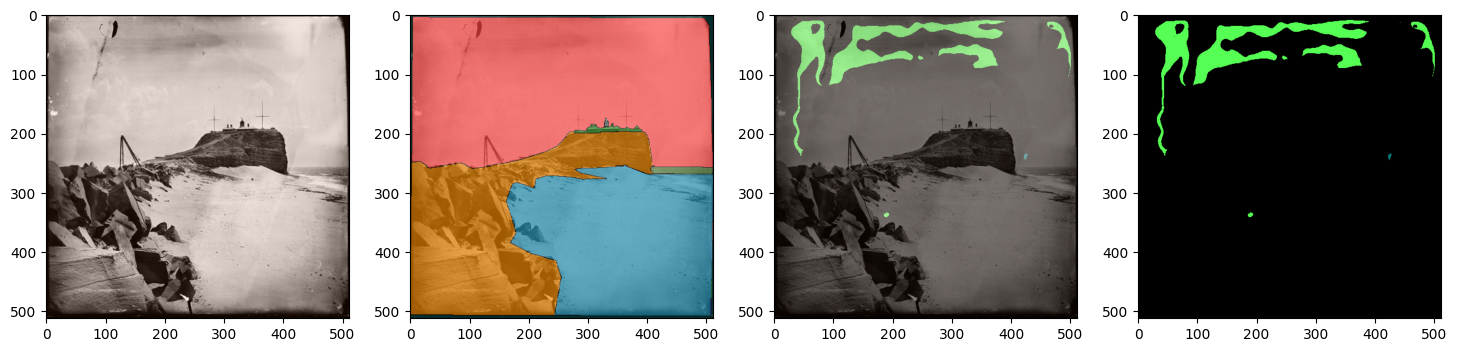

1/1 [==============================] - 0s 31ms/step


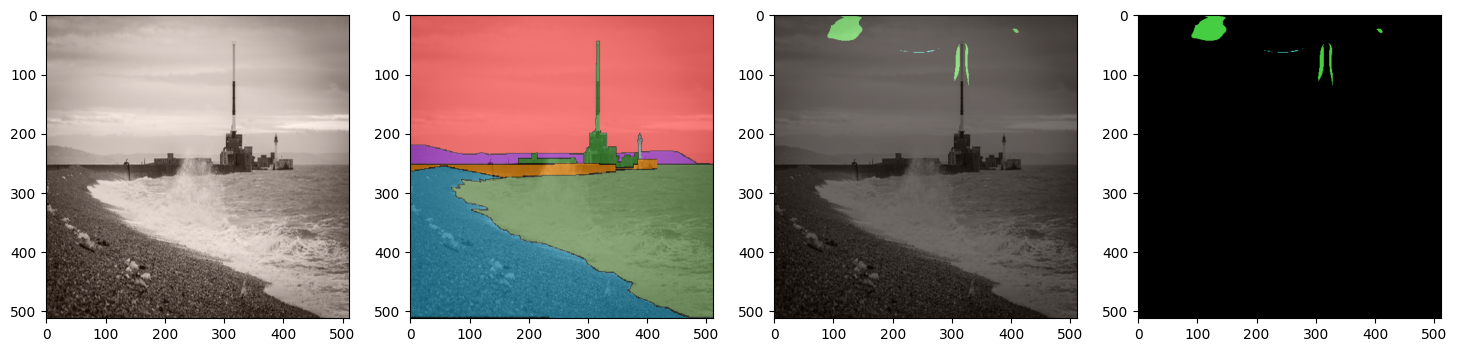

1/1 [==============================] - 0s 35ms/step


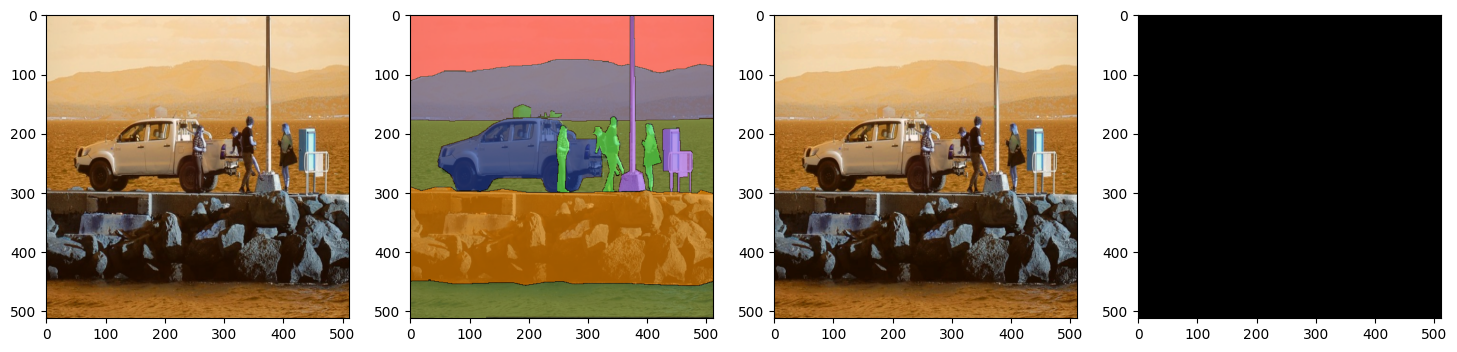

1/1 [==============================] - 0s 33ms/step


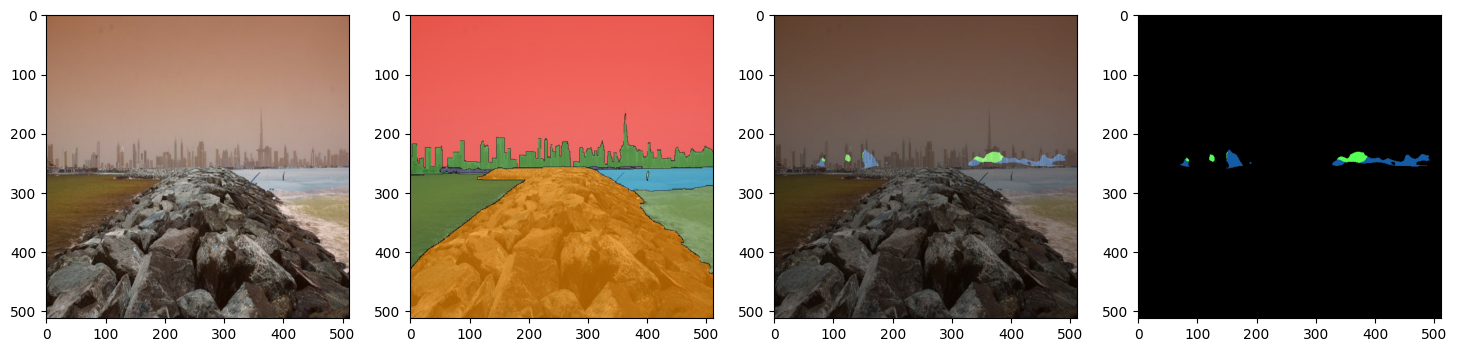

In [26]:
plot_predictions(train_images[:4], train_masks[:4], colormap, model=model)

1/1 [==============================] - 0s 29ms/step


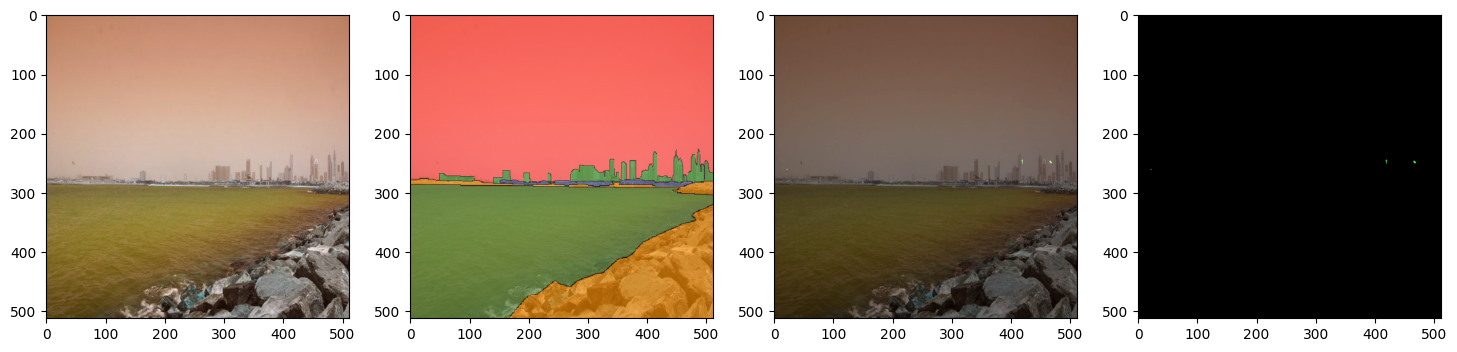

1/1 [==============================] - 0s 29ms/step


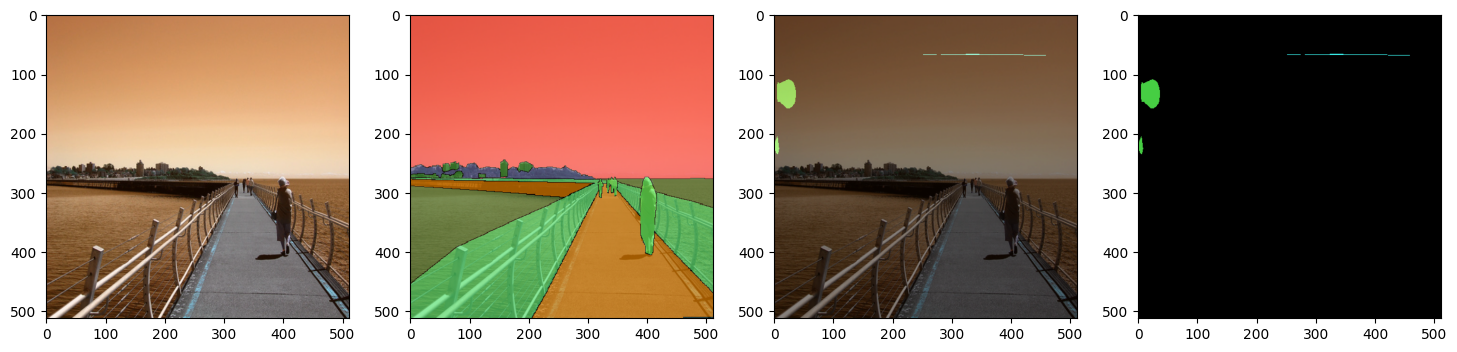

1/1 [==============================] - 0s 29ms/step


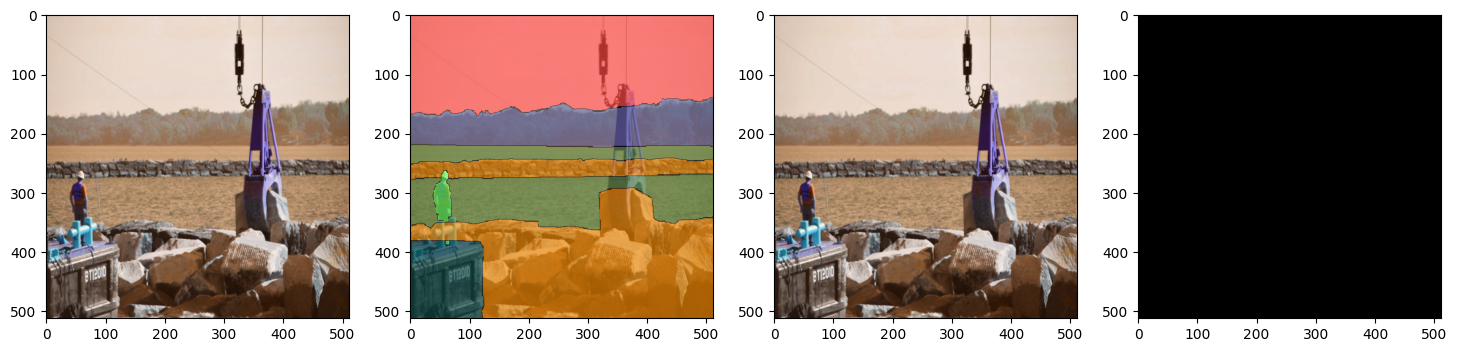

1/1 [==============================] - 0s 27ms/step


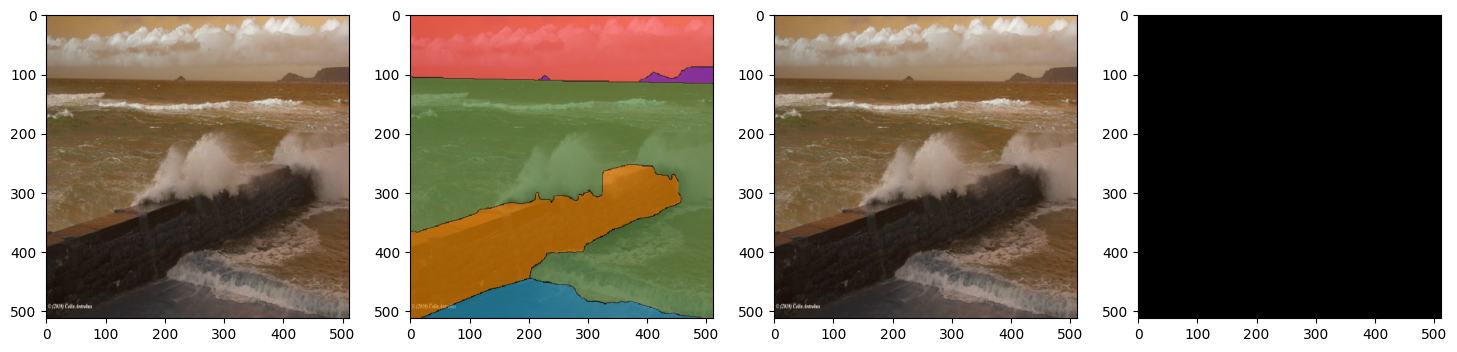

In [27]:
plot_predictions(val_images[:4], val_masks[:4], colormap, model=model)